# YOLO11: бейзлайн (one-stage, anchor-free)

Бейзлайн. Налаштування стандартні (`imgsz=640`), щоб потім було видно, що дає кожна зміна з EDA.

Протокол, однаковий для всіх моделей:
- train: 56 відео, кожен 5-й кадр (обґрунтування в `01_eda`, розділ 9);
- val: 7 відео, усі кадри;
- оцінка: COCO mAP, AP50, AP_small через `pycocotools`, ignored regions передаються як `iscrowd = 1`;
- бюджет: однакова кількість епох.


## 0. Налаштування

In [1]:
%pip install -q ultralytics pycocotools

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import time
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import torch

os.environ["WANDB_MODE"] = "disabled"
os.environ["YOLO_VERBOSE"] = "False"

import ultralytics
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

ultralytics.settings.update({"wandb": False})

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

MODEL = "yolo11s.pt"
RUN_NAME = "yolo11s_640"
IMGSZ = 640
EPOCHS = 30
STEP = 5

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає")

ultralytics 8.4.193 | torch 2.11.0+cu128 | GPU: Tesla T4


Шукаємо дані так само, як в `01_eda`. Усі результати пишемо в `/kaggle/working`, звідти Kaggle зберігає їх після запуску.

In [3]:
ROOT = next(
    path.parent
    for pattern in ["*/test_images.csv", "*/*/test_images.csv", "*/*/*/test_images.csv"]
    for path in Path("/kaggle/input").glob(pattern)
)
OUT = Path("/kaggle/working")
print(ROOT)

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Дані для тренування

Ultralytics вміє брати список картинок з текстового файлу, а мітки сам шукає в сусідній папці `labels`. Тому нічого не копіюємо: робимо список кожного 5-го кадру train і список усіх кадрів val.

In [4]:
def frame_list(split):
    return pl.DataFrame({"path": sorted(str(path) for path in (ROOT / split / "images").rglob("*.jpg"))}).with_columns(
        video=pl.col("path").str.split("/").list.get(-2)
    )


train_frames = frame_list("train").filter((pl.int_range(pl.len()).over("video") % STEP) == 0)
val_frames = frame_list("val")

(OUT / "train_list.txt").write_text("\n".join(train_frames["path"]))
(OUT / "val_list.txt").write_text("\n".join(val_frames["path"]))

(OUT / "data.yaml").write_text(
    f"train: {OUT / 'train_list.txt'}\n"
    f"val: {OUT / 'val_list.txt'}\n"
    f"nc: {len(CLASSES)}\n"
    f"names: {json.dumps(CLASSES)}\n"
)

print("train:", train_frames.height, "кадрів з", train_frames["video"].n_unique(), "відео")
print("val:", val_frames.height, "кадрів з", val_frames["video"].n_unique(), "відео")

train: 4868 кадрів з 56 відео
val: 2846 кадрів з 7 відео


## 2. Тренування

YOLO11 — anchor-free детектор: замість заготовлених рамок кожна точка карти ознак передбачає відстані до країв об'єкта. Які точки вважати "відповідальними" за об'єкт, вирішує task-aligned assigner (з TOOD): він бере точки, де одночасно високі і впевненість класу, і IoU рамки.

Стартуємо з ваг, натренованих на COCO. Крім кількості епох і seed, все за замовчуванням.

In [5]:
model = YOLO(MODEL)
start = time.time()
model.train(
    data=str(OUT / "data.yaml"),
    imgsz=IMGSZ,
    epochs=EPOCHS,
    seed=SEED,
    deterministic=True,
    workers=4,
    device=0,
    project=str(OUT / "runs"),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
)
train_hours = (time.time() - start) / 3600
print(f"тренування: {train_hours:.2f} год")

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


тренування: 1.05 год


Криві тренування: як змінювались лоси і mAP на val по епохах. Ці ж дані потім знадобляться, щоб порівняти швидкість навчання з RT-DETR.

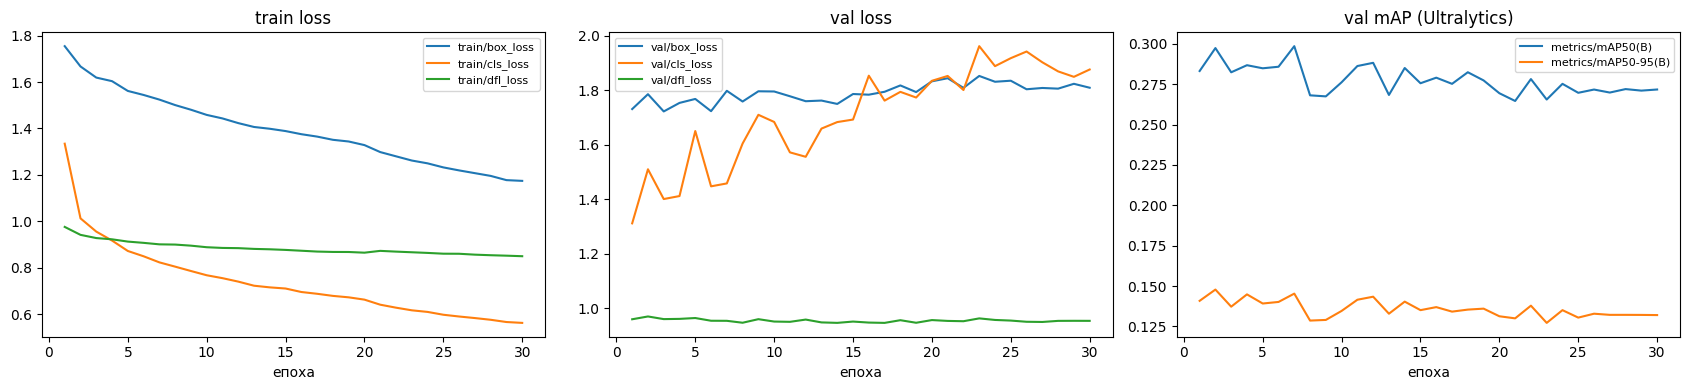

In [6]:
run_dir = OUT / "runs" / RUN_NAME
history = pl.read_csv(run_dir / "results.csv")
history = history.rename({name: name.strip() for name in history.columns})

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name in ["train/box_loss", "train/cls_loss", "train/dfl_loss"]:
    axes[0].plot(history["epoch"], history[name], label=name)
for name in ["val/box_loss", "val/cls_loss", "val/dfl_loss"]:
    axes[1].plot(history["epoch"], history[name], label=name)
for name in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
    axes[2].plot(history["epoch"], history[name], label=name)
axes[0].set_title("train loss")
axes[1].set_title("val loss")
axes[2].set_title("val mAP (Ultralytics)")
for ax in axes:
    ax.set_xlabel("епоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Оцінка на val за нашим протоколом

Метрики Ultralytics не враховують ignored regions і не рахують AP_small, тому робимо свою оцінку:
- передбачаємо всі кадри val з низьким порогом впевненості (0.001), бо mAP сам перебирає пороги;
- `max_det=500`, як на Kaggle;
- переводимо рамки в COCO-формат і рахуємо `COCOeval` з оригінальним `annotations_coco.json` (там ignored regions уже позначені `iscrowd = 1`);
- у `COCOeval` ставимо ліміт 500 детекцій на кадр замість стандартних 100, бо в нас буває до 180 об'єктів на кадрі.
- кадри подаємо порціями по 16: якщо передати весь список одразу, Ultralytics завантажує всі картинки в пам'ять, і на кадрах 4K закінчується RAM;

In [7]:
best = YOLO(run_dir / "weights" / "best.pt")

val_coco = json.loads((ROOT / "val" / "annotations_coco.json").read_text())
image_ids = {"/".join(Path(image["file_name"]).parts[-2:]): image["id"] for image in val_coco["images"]}

val_paths = val_frames["path"].to_list()
detections = []
speeds = []
for chunk_start in range(0, len(val_paths), 16):
    for result in best.predict(source=val_paths[chunk_start:chunk_start + 16], batch=16, imgsz=IMGSZ, conf=0.001, max_det=500, verbose=False, device=0):
        speeds.append(sum(result.speed.values()))
        boxes = result.boxes.xyxy.cpu().numpy()
        detections += [
            {"image_id": image_ids["/".join(Path(result.path).parts[-2:])], "category_id": int(cls) + 1, "bbox": [round(float(x1), 2), round(float(y1), 2), round(float(x2 - x1), 2), round(float(y2 - y1), 2)], "score": round(float(score), 4)}
            for (x1, y1, x2, y2), cls, score in zip(boxes, result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy())
        ]

(OUT / f"val_predictions_{RUN_NAME}.json").write_text(json.dumps(detections))
ms_per_image = float(np.mean(speeds))
print(len(detections), "детекцій на", len(image_ids), "кадрах;", f"{ms_per_image:.1f} ms/кадр")

1021822 детекцій на 2846 кадрах; 8.0 ms/кадр


In [8]:
ground_truth = COCO(str(ROOT / "val" / "annotations_coco.json"))
evaluator = COCOeval(ground_truth, ground_truth.loadRes(str(OUT / f"val_predictions_{RUN_NAME}.json")), "bbox")
evaluator.params.maxDets = [1, 100, 500]
evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

loading annotations into memory...
Done (t=0.43s)
creating index...
index created!
Loading and preparing results...
DONE (t=5.56s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=311.38s).
Accumulating evaluation results...
DONE (t=13.04s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.137
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.273
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.122
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.050
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.118
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.269
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.074
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.263
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxD

Зводимо головні цифри в один рядок і зберігаємо в файл. Такий самий рядок буде в кожному наступному ноутбуці, з них потім збираємо загальну таблицю порівняння моделей.

In [9]:
stats = evaluator.stats
result_row = {
    "run": RUN_NAME,
    "model": MODEL,
    "imgsz": IMGSZ,
    "epochs": EPOCHS,
    "train_frames": train_frames.height,
    "mAP": round(stats[0], 4),
    "AP50": round(stats[1], 4),
    "AP75": round(stats[2], 4),
    "AP_small": round(stats[3], 4),
    "AP_medium": round(stats[4], 4),
    "AP_large": round(stats[5], 4),
    "AR500": round(stats[8], 4),
    "ms_per_image": round(ms_per_image, 1),
    "train_hours": round(train_hours, 2),
}
(OUT / f"result_{RUN_NAME}.json").write_text(json.dumps(result_row, indent=2))
pl.DataFrame([result_row])

run,model,imgsz,epochs,train_frames,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,train_hours
str,str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""yolo11s_640""","""yolo11s.pt""",640,30,4868,0.1375,0.2733,0.1224,0.0498,0.1177,0.2685,0.2686,8.0,1.05


AP по кожному класу окремо: середній mAP може ховати класи, які модель майже не знаходить.

In [10]:
precision = evaluator.eval["precision"][:, :, :, 0, -1]
pl.DataFrame(
    [
        {
            "class": name,
            "AP": round(float(np.mean(precision[:, :, i][precision[:, :, i] > -1])), 4) if (precision[:, :, i] > -1).any() else None,
            "AP50": round(float(np.mean(precision[0, :, i][precision[0, :, i] > -1])), 4) if (precision[0, :, i] > -1).any() else None,
        }
        for i, name in enumerate(CLASSES)
    ]
)

class,AP,AP50
str,f64,f64
"""person""",0.1972,0.5201
"""bicycle""",0.067,0.1454
"""car""",0.3329,0.5395
"""van""",0.0814,0.128
"""truck""",0.1301,0.2188
"""tricycle""",0.155,0.338
"""bus""",0.0686,0.0825
"""motor""",0.0733,0.2144


## 4. Сабміт на Kaggle

Передбачаємо всі кадри test з тими самими налаштуваннями. Формат рядка: `class score x y width height`, де (x, y) — лівий верхній кут у пікселях оригінального кадру. Ultralytics повертає рамки вже в пікселях оригіналу, тож лишається перевести кути в ширину і висоту. Кадри без детекцій лишаються з порожнім рядком.

In [11]:
test_images = pl.read_csv(ROOT / "test_images.csv")
test_ids = {"/".join(Path(file_name).parts[-2:]): image_id for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()}

test_paths = [str(ROOT / file_name) for file_name in test_images["file_name"]]
predictions = {}
for chunk_start in range(0, len(test_paths), 16):
    for result in best.predict(source=test_paths[chunk_start:chunk_start + 16], batch=16, imgsz=IMGSZ, conf=0.001, max_det=500, verbose=False, device=0):
        boxes = result.boxes.xyxy.cpu().numpy()
        predictions[test_ids["/".join(Path(result.path).parts[-2:])]] = " ".join(
            f"{int(cls)} {score:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}"
            for (x1, y1, x2, y2), cls, score in zip(boxes, result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy())
        )

submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(predictions, default="")
)
submission.write_csv(OUT / "submission.csv")
print(submission.height, "рядків,", (submission["PredictionString"] == "").sum(), "порожніх")
submission.head()

3811 рядків, 0 порожніх


image_id,PredictionString
str,str
"""clip_001_0000001""","""0 0.6611 1710.6 800.4 55.5 136…"
"""clip_001_0000002""","""0 0.6771 1664.0 792.7 63.1 153…"
"""clip_001_0000003""","""0 0.6406 713.0 903.0 72.0 168.…"
"""clip_001_0000004""","""0 0.6468 760.1 902.9 71.5 169.…"
"""clip_001_0000005""","""0 0.6491 674.7 919.6 65.9 156.…"


Перевірка формату перед відправкою: кількість рядків як у `test_images.csv`, у кожній групі 6 чисел, класи від 0 до 7, рамки не виходять за межі кадру.

In [12]:
rows = (
    submission.join(test_images.select("image_id", "width", "height"), on="image_id")
    .filter(pl.col("PredictionString") != "")
    .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
)
boxes = rows.select(
    "width",
    "height",
    *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(["cls", "score", "x", "y", "w", "h"])],
).explode("cls", "score", "x", "y", "w", "h")

{
    "рядків як у test_images.csv": submission.height == test_images.height,
    "кількість чисел кратна 6": rows.select((pl.col("values").list.len() % 6 == 0).all()).item(),
    "не більше 500 рамок на кадр": rows.select((pl.col("values").list.len() <= 6 * 500).all()).item(),
    "класи від 0 до 7": boxes["cls"].is_between(0, 7).all(),
    "score від 0 до 1": boxes["score"].is_between(0, 1).all(),
    "рамки в межах кадру": boxes.select(
        ((pl.col("x") >= -1) & (pl.col("y") >= -1) & (pl.col("x") + pl.col("w") <= pl.col("width") + 1) & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)).all()
    ).item(),
}

{'рядків як у test_images.csv': True,
 'кількість чисел кратна 6': True,
 'не більше 500 рамок на кадр': True,
 'класи від 0 до 7': True,
 'score від 0 до 1': True,
 'рамки в межах кадру': True}